# Дообучение rubert-tiny2: название товара из чека → категория

Задача — классификация коротких текстов (строк кассового чека) на 8 категорий.
Берём предобученную модель [cointegrated/rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2)
и дообучаем её на нашем датасете. Для сравнения обучаем простой baseline — TF-IDF + логистическая регрессия.

In [15]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, f1_score, ConfusionMatrixDisplay
from transformers import AutoTokenizer, AutoModelForSequenceClassification

from preprocess import normalize  # та же предобработка используется в боте

MODEL_NAME = "cointegrated/rubert-tiny2"
SAVE_DIR = "model"
EPOCHS = 25
BATCH_SIZE = 32
LR = 1e-4
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## 1. Данные
`text` — строка из чека, `category` — категория, `group` — номер исходного товара.
У одного товара несколько вариантов написания (регистр, сокращения, артикулы, ошибки OCR).

In [16]:
df = pd.read_csv("data/products.csv")
print(df.shape, "товаров:", df["group"].nunique())
print(df["category"].value_counts())

(4320, 3) товаров: 889
category
еда            720
бытовое        598
развлечения    588
здоровье       544
другое         493
одежда         488
напитки        462
транспорт      427
Name: count, dtype: int64


## 2. Предобработка
rubert-tiny2 обучалась на обычном тексте, а строки чеков написаны КАПСОМ, с артикулами и ошибками OCR.
Поэтому перед моделью приводим текст к нижнему регистру, убираем артикулы и номера позиций,
исправляем типичные ошибки OCR (цифра или латинская буква внутри русского слова).
Функция `normalize` лежит в `preprocess.py`, бот использует её же.

In [17]:
df["clean"] = df["text"].map(normalize)
df[["text", "clean", "category"]].sample(10, random_state=SEED)

,text,clean,category
461,*2627181 СВИНИНА ШЕЙКА ОХЛ,свинина шейка охл,еда
109,*2432212 ЗОНТ СКЛАДНОЙ,зонт складной,одежда
2295,*3592668 КРОССО БЕГОВЫЕ,кроссо беговые,одежда
2589,БАГЕТ ФРАНЦУ,багет францу,еда
157,1. ЧЕБУРЕК С МЯСОМ,чебурек с мясом,еда
2683,ДЕЗОДОРАНТ REXONA СПРЕЙ 150МЛ,дезодорант rexona спрей 150мл,бытовое
3914,Энтеросгель паста,энтеросгель паста,здоровье
3162,*1652177 ПЕЛЬМЕНИ СИБИРСКАЯ КОЛЛЕКЦИЯ 700Г,пельмени сибирская коллекция 700г,еда
2884,ГОВЯД ЛОПАТКА ОХЛ 1КГ,говяд лопатка охл 1кг,еда
2238,*8215511 СНУД,снуд,одежда


## 3. Разбиение train / validation / test
Делим **по группам**: все варианты одного товара попадают только в одну часть.
Иначе модель видела бы в обучении почти ту же строку, что и в тесте, и метрики были бы завышены.

- **train** — обучение,
- **validation** — выбор лучшей эпохи,
- **test** — итоговая оценка (не используется ни для обучения, ни для выбора эпохи).

In [18]:
def group_split(data, test_size):
    splitter = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=SEED)
    a, b = next(splitter.split(data, groups=data["group"]))
    return data.iloc[a], data.iloc[b]

train_full, test_df = group_split(df, 0.2)
train_df, val_df = group_split(train_full, 0.15)

labels = sorted(df["category"].unique())
label2id = {l: i for i, l in enumerate(labels)}
id2label = {i: l for l, i in label2id.items()}

print("train:", len(train_df), " val:", len(val_df), " test:", len(test_df))

train: 2928  val: 529  test: 863


## 4. Baseline: TF-IDF по символьным n-граммам + логистическая регрессия

In [19]:
tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4))
X_train = tfidf.fit_transform(train_full["clean"])
X_test = tfidf.transform(test_df["clean"])

logreg = LogisticRegression(max_iter=2000, C=10)
logreg.fit(X_train, train_full["category"])
baseline_pred = logreg.predict(X_test)

print(classification_report(test_df["category"], baseline_pred))

              precision    recall  f1-score   support

     бытовое       0.76      0.78      0.77       130
      другое       0.65      0.57      0.61       108
         еда       0.73      0.88      0.80       161
    здоровье       0.57      0.73      0.64        96
     напитки       0.94      0.62      0.75        77
      одежда       0.62      0.44      0.51       103
 развлечения       0.65      0.67      0.66        97
   транспорт       0.63      0.65      0.64        91

    accuracy                           0.69       863
   macro avg       0.69      0.67      0.67       863
weighted avg       0.69      0.69      0.68       863



## 5. Дообучение rubert-tiny2

In [20]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(labels), id2label=id2label, label2id=label2id
).to(device)


def batches(data, batch_size, shuffle=False):
    """Нарезаем датафрейм на батчи и токенизируем."""
    idx = np.random.permutation(len(data)) if shuffle else np.arange(len(data))
    for start in range(0, len(data), batch_size):
        part = data.iloc[idx[start:start + batch_size]]
        enc = tokenizer(list(part["clean"]), padding=True, truncation=True, max_length=64, return_tensors="pt")
        enc["labels"] = torch.tensor([label2id[c] for c in part["category"]])
        yield {k: v.to(device) for k, v in enc.items()}


def predict(texts, batch_size=64):
    """texts — уже нормализованные строки."""
    model.eval()
    result = []
    with torch.no_grad():
        for start in range(0, len(texts), batch_size):
            enc = tokenizer(texts[start:start + batch_size], padding=True, truncation=True,
                            max_length=64, return_tensors="pt").to(device)
            result += model(**enc).logits.argmax(-1).tolist()
    return [id2label[i] for i in result]

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Обучаем `EPOCHS` эпох и после каждой считаем macro-F1 на **validation**.
Запоминаем веса лучшей эпохи — так мы не зависим от того, переобучилась ли модель к концу.

In [21]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
history = []
best_f1, best_state, best_epoch = -1, None, 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    losses = []
    for batch in batches(train_df, BATCH_SIZE, shuffle=True):
        loss = model(**batch).loss
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        losses.append(loss.item())

    val_f1 = f1_score(val_df["category"], predict(list(val_df["clean"])), average="macro")
    history.append({"epoch": epoch, "train_loss": np.mean(losses), "val_f1": val_f1})
    print(f"epoch {epoch:2d}: loss={np.mean(losses):.4f}  val macro-F1={val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1, best_epoch = val_f1, epoch
        best_state = copy.deepcopy(model.state_dict())

model.load_state_dict(best_state)
print(f"Лучшая эпоха: {best_epoch}, val macro-F1 = {best_f1:.4f}")

epoch  1: loss=1.3641  val macro-F1=0.7007
epoch  2: loss=0.2906  val macro-F1=0.7436
epoch  3: loss=0.0730  val macro-F1=0.8429
epoch  4: loss=0.0276  val macro-F1=0.8015
epoch  5: loss=0.0154  val macro-F1=0.7891
epoch  6: loss=0.0101  val macro-F1=0.8289
epoch  7: loss=0.0072  val macro-F1=0.7612
epoch  8: loss=0.0055  val macro-F1=0.7595
epoch  9: loss=0.0042  val macro-F1=0.7868
epoch 10: loss=0.0035  val macro-F1=0.7915
epoch 11: loss=0.0028  val macro-F1=0.8082
epoch 12: loss=0.0045  val macro-F1=0.7141
epoch 13: loss=0.0130  val macro-F1=0.7116
epoch 14: loss=0.0128  val macro-F1=0.7803
epoch 15: loss=0.0089  val macro-F1=0.7819
epoch 16: loss=0.0038  val macro-F1=0.8183
epoch 17: loss=0.0025  val macro-F1=0.8117
epoch 18: loss=0.0015  val macro-F1=0.7609
epoch 19: loss=0.0010  val macro-F1=0.7632
epoch 20: loss=0.0009  val macro-F1=0.7688
epoch 21: loss=0.0008  val macro-F1=0.7756
epoch 22: loss=0.0008  val macro-F1=0.7756
epoch 23: loss=0.0007  val macro-F1=0.7756
epoch 24: l

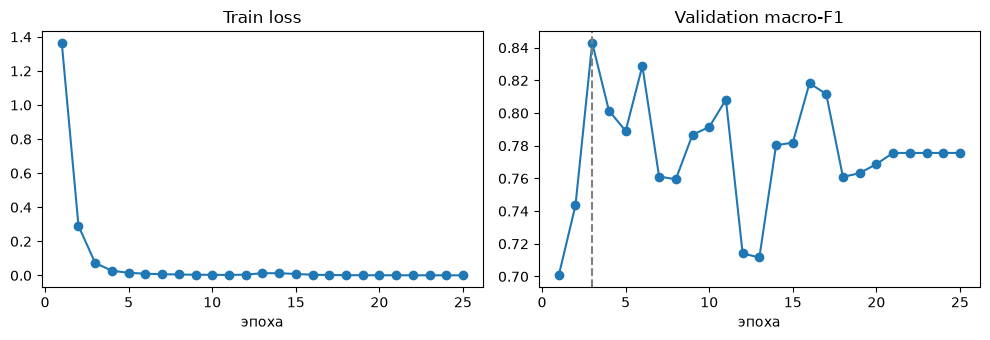

In [22]:
hist = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist["epoch"], hist["train_loss"], marker="o"); ax[0].set_title("Train loss"); ax[0].set_xlabel("эпоха")
ax[1].plot(hist["epoch"], hist["val_f1"], marker="o"); ax[1].set_title("Validation macro-F1"); ax[1].set_xlabel("эпоха")
ax[1].axvline(best_epoch, color="gray", linestyle="--")
plt.tight_layout(); plt.show()

## 6. Оценка на test и сравнение с baseline

In [23]:
bert_pred = predict(list(test_df["clean"]))
print(classification_report(test_df["category"], bert_pred))

              precision    recall  f1-score   support

     бытовое       0.85      0.82      0.83       130
      другое       0.81      0.77      0.79       108
         еда       0.86      0.89      0.87       161
    здоровье       0.68      0.74      0.71        96
     напитки       0.93      0.82      0.87        77
      одежда       0.67      0.80      0.73       103
 развлечения       0.83      0.77      0.80        97
   транспорт       0.77      0.71      0.74        91

    accuracy                           0.80       863
   macro avg       0.80      0.79      0.79       863
weighted avg       0.80      0.80      0.80       863



In [24]:
comparison = pd.DataFrame({
    "модель": ["TF-IDF + LogReg", "rubert-tiny2 (fine-tune)"],
    "accuracy": [accuracy_score(test_df["category"], baseline_pred), accuracy_score(test_df["category"], bert_pred)],
    "macro-F1": [f1_score(test_df["category"], baseline_pred, average="macro"),
                 f1_score(test_df["category"], bert_pred, average="macro")],
}).round(3)
comparison

,модель,accuracy,macro-F1
0,TF-IDF + LogReg,0.686,0.672
1,rubert-tiny2 (fine-tune),0.797,0.793


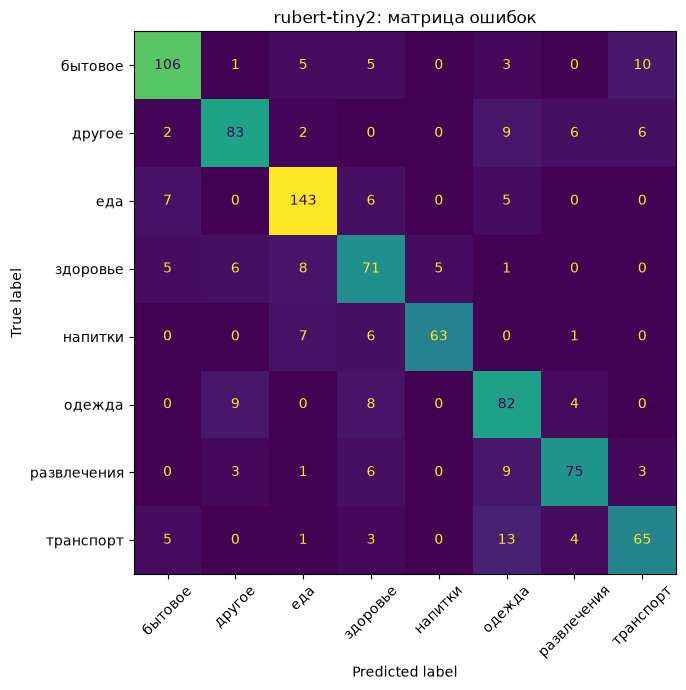

In [25]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(test_df["category"], bert_pred, labels=labels,
                                        xticks_rotation=45, ax=ax, colorbar=False)
ax.set_title("rubert-tiny2: матрица ошибок")
plt.tight_layout(); plt.show()

In [26]:
errors = test_df.assign(pred=bert_pred).query("pred != category")
print("Ошибок:", len(errors), "из", len(test_df))
errors[["text", "clean", "category", "pred"]].head(20)

Ошибок: 175 из 863


,text,clean,category,pred
22,ПЕЙНТБОЛ,пейнтбол,развлечения,здоровье
27,ВЕДРО ПЛАСТИКОВОЕ 10Л,ведро пластиковое 10л,бытовое,транспорт
37,5. КОЛБ ДОКТОР ВАР 400Г,колб доктор вар 400г,еда,здоровье
62,ФОЛЬГА АЛЮМИНИЕВАЯ 10М,фольга алюминиевая 10м,бытовое,транспорт
74,9. ТЕРМОБЕЛЬЕ,термобелье,одежда,здоровье
128,Горячий шоколад,горячий шоколад,напитки,еда
129,Бенгальские огни,бенгальские огни,развлечения,одежда
159,Кошелек,кошелек,одежда,другое
174,БОРЩ ПОРЦИЯ,борщ порция,еда,одежда
175,Пленка пищевая 30м,пленка пищевая 30м,бытовое,еда


## 7. Сохранение модели для бота

In [27]:
model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
print("Модель сохранена в папку", SAVE_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Модель сохранена в папку model


In [28]:
examples = ["МОЛ ДОМИК В ДЕР 3,2% 950МЛ", "БЕНЗИН АИ-95-К5", "ПАКЕТ МАЙКА", "ОТРИВИН СПРЕЙ НАЗАЛ",
            "ФУТБ МУЖ ХЛОПОК", "БИЛЕТ КИНО 3D", "ПЕПСИ 0,5Л", "ПОРОШОК ЛОСК 2,7КГ"]
pd.DataFrame({"текст": examples, "категория": predict([normalize(e) for e in examples])})

,текст,категория
0,"МОЛ ДОМИК В ДЕР 3,2% 950МЛ",еда
1,БЕНЗИН АИ-95-К5,транспорт
2,ПАКЕТ МАЙКА,другое
3,ОТРИВИН СПРЕЙ НАЗАЛ,здоровье
4,ФУТБ МУЖ ХЛОПОК,одежда
5,БИЛЕТ КИНО 3D,развлечения
6,"ПЕПСИ 0,5Л",напитки
7,"ПОРОШОК ЛОСК 2,7КГ",бытовое
